# D3S Dataset Exploration

Task T0202 inventory review for the Driver Drowsiness Detection System. The notebook reads `data/metadata/d3s_inventory.csv`, summarizes video-level metadata, and records split guidance that keeps subject/video boundaries intact.

In [1]:
from collections import Counter
import csv
from pathlib import Path
import matplotlib.pyplot as plt

repo_root = Path.cwd().resolve()
inventory_path = repo_root / 'data' / 'metadata' / 'd3s_inventory.csv'
with inventory_path.open(newline='', encoding='utf-8') as csv_file:
    records = list(csv.DictReader(csv_file))

print(f'Loaded {len(records)} video record(s) from {inventory_path}')

Loaded 1 video record(s) from F:\Study Materials\Môn Ngành\PY NC\PY_ADV_PJ_GR\data\metadata\d3s_inventory.csv


In [2]:
for record in records:
    print(
        record['video_id'],
        record['relative_path'],
        record['subject_id'],
        record['label'],
        record['resolution'],
        record['fps'],
        record['total_frames'],
        record['duration_sec'],
    )

d3s_0001 d3s_video_dataset.mp4 UNKNOWN UNKNOWN 1920x1080 23.976024 4673 194.903042


## Metadata Provenance

Subject and class labels are parsed only from path or filename tokens such as `subject_02/yawning/sample.mp4`. The current local D3S artifact is a single monolithic MP4 named `d3s_video_dataset.mp4`, so its subject and label fields remain `UNKNOWN` until the team imports a structured video/frame release or adds verified segment annotations.

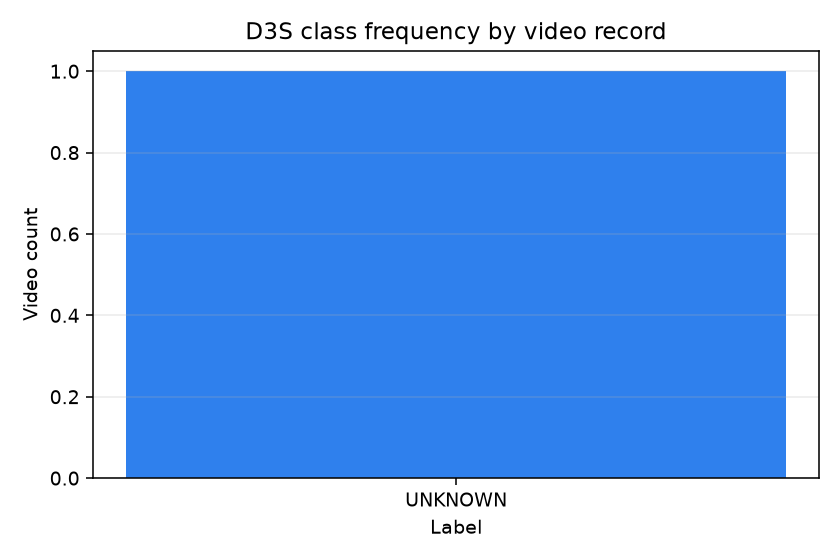

In [3]:
label_counts = Counter(
    record['label'] for record in records
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(label_counts.keys(), label_counts.values(), color='#2f80ed')
ax.set_title('D3S class frequency by video record')
ax.set_xlabel('Label')
ax.set_ylabel('Video count')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

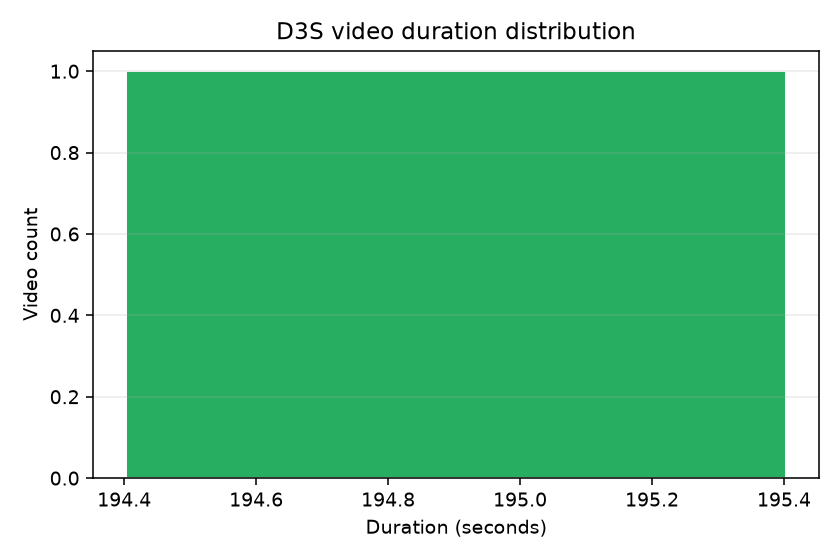

In [4]:
durations = [float(record['duration_sec']) for record in records]
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(durations, bins=max(1, min(8, len(durations))), color='#27ae60', edgecolor='white')
ax.set_title('D3S video duration distribution')
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Video count')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

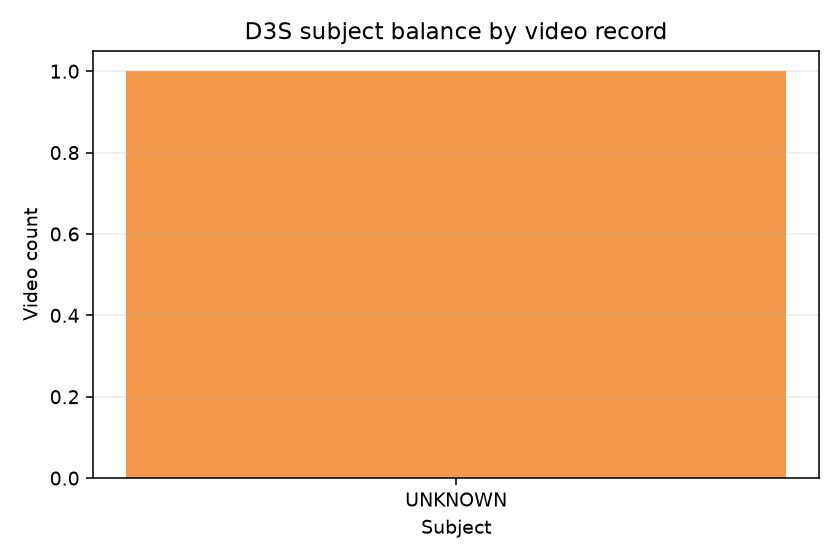

In [5]:
subject_counts = Counter(
    record['subject_id'] for record in records
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(subject_counts.keys(), subject_counts.values(), color='#f2994a')
ax.set_title('D3S subject balance by video record')
ax.set_xlabel('Subject')
ax.set_ylabel('Video count')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

## Subject-Level Split Guidance

- Split by subject when subject IDs are available: for example, train on two subjects and reserve the third subject for validation or testing.
- If a subject cannot be separated, split by complete source video or verified contiguous session, never by randomly shuffled frames.
- Keep neighboring frames from the same driver/session in the same partition so temporal signals do not leak across evaluation sets.
- Report `UNKNOWN` and invalid records separately during evaluation instead of dropping them silently.

In [6]:
unparsed = [
    record for record in records
    if record['subject_id'] == 'UNKNOWN'
    or record['label'] == 'UNKNOWN'
]
print(f'Rows needing verified labels: {len(unparsed)}')
for record in unparsed:
    print(record['relative_path'])

Rows needing verified labels: 1
d3s_video_dataset.mp4
